In [29]:
# ──  Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')


Dependencies OK.


In [30]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cpu


---
## Step 1 — Data Loading, Curation & Label Assignment


In [31]:
# ──  Load ────────────────────────────────────────────────────────────────
df_raw = pd.read_csv('combined_hepg2_casepase.csv',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())
print(df_raw['PUBCHEM_ACTIVITY_SCORE'].describe())


Raw rows : 7,716
PUBCHEM_ACTIVITY_OUTCOME
Inactive        7172
Inconclusive     303
Active           241
Name: count, dtype: int64
count    7716.000000
mean        2.222136
std        10.344257
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       100.000000
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64


In [32]:
# ──   SMILES + deduplication ──────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi)) #converts to mol object, returns None if invalid
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi'])
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')
df = df.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')


[09:08:20] WARNING: not removing hydrogen atom without neighbors


After parse : 7,716  (removed 0 invalid SMILES)
After dedup : 7,714


Removed 294 inconclusive
Active   (1): 249
Inactive (0): 7,171
Ratio       : 28.8:1


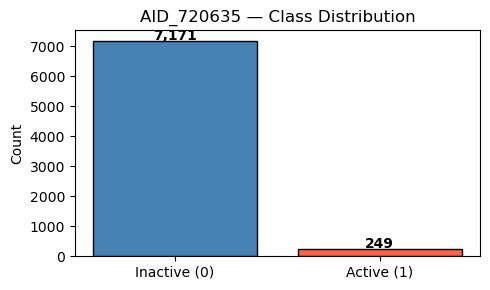

In [33]:
# ── Binary Labels
#  Active (score >= 40) -> 1 | Inactive (score = 0) -> 0 | Inconclusive -> drop
df['label'] = df['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
n_inc = df['label'].isna().sum()
df = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Removed {n_inc:,} inconclusive')
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'],[n_ina,n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b,v in zip(bars,[n_ina,n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('AID_720635 — Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('class_dist.png',dpi=150); plt.show()


---
## Step 2 — Feature Engineering

### 2A. Morgan Fingerprints (ECFP4) — for Classical ML
### 2B. Rich Atom/Bond Graph Features — for GNN


In [34]:
# ── 5. Morgan ECFP4 (2048 bits) ─────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')


[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix : (7420, 2048)
FP density         : 0.0135


[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerator
[09:08:21] DEPRECATION WARNING: please use MorganGenerat

In [35]:
# ──  Rich Atom Features (14-dim) & Bond Features (6-dim) — for GNN ─────────
#
#  14 atom features 
#    Atomic num one-hot (C,N,O,S,F,P,Cl,Br,I,other=10),
#    degree (0-5), formal charge, hybridization one-hot (SP/SP2/SP3/other=4),
#    is_aromatic, is_in_ring, total_Hs (0-4), normalized mass
#
#  6 bond features:
#    bond type one-hot (single/double/triple/aromatic=4),
#    is_conjugated, is_in_ring
#
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass   # 'other' → all zeros
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim (+other)
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5) #no of bonds this atom has
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge() #chareg positve or nehative or zero
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 10+6+3+4+4 = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC
]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)  # 4-dim
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

# Test dimensions
from rdkit.Chem import MolFromSmiles
_mol = MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')


Atom feature dim : 27
Bond feature dim : 6


In [36]:
# ── 7. Build Graph Dataset ───────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    # Atom features
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    # Bond features + bidirectional edges
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')


[09:08:22] WARNING: not removing hydrogen atom without neighbors


Graphs built: 7,420
Example: Data(x=[5, 27], edge_index=[2, 8], edge_attr=[8, 6], y=[1])


---
## Step 3 — 80/20/20 Split + Downsampling


In [37]:
# ── 8. 20% External Test Split ───────────────────────────────────────────────
X_pool, X_test, y_pool, y_test = train_test_split(
    X_fp, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

# Parallel split for graph data (using same indices)
idx_all   = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (act={( y_pool==1).sum()}, ina={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (act={(y_test==1).sum()}, ina={(y_test==0).sum()})')


Pool : 5,936  (act=199, ina=5737)
Test : 1,484  (act=50, ina=1434)


In [38]:
# ── Print Test Set Values ─────────────────────────────────────────────────────
df_test = df.iloc[idx_test].reset_index(drop=True).copy()
df_test['label'] = y_test

print(f'Test set size : {len(df_test):,} compounds')
print(f'X_test shape  : {X_test.shape}   (compounds × ECFP4 bits)')
print(f'y_test shape  : {y_test.shape}')
print(f'\nClass distribution:')
print(f'  Active   (1): {(y_test == 1).sum():,}')
print(f'  Inactive (0): {(y_test == 0).sum():,}')

print(f'\n── First 10 test set compounds ──')
display(df_test[['PUBCHEM_CID', 'csmi', 'PUBCHEM_ACTIVITY_SCORE', 'label']].head(20))

print(f'\n── Fingerprint values (X_test) — first 5 rows, first 20 bits ──')
print(X_test[:5, :20])

print(f'\n── Labels (y_test) — first 20 values ──')
print(y_test[:50])


Test set size : 1,484 compounds
X_test shape  : (1484, 2048)   (compounds × ECFP4 bits)
y_test shape  : (1484,)

Class distribution:
  Active   (1): 50
  Inactive (0): 1,434

── First 10 test set compounds ──


,PUBCHEM_CID,csmi,PUBCHEM_ACTIVITY_SCORE,label
0,439280,N[C@@H](Cc1c[nH]c2ccc(O)cc12)C(=O)O,0,0
1,71651,O=C(O)CCNC(=O)c1ccccc1,0,0
2,21804,CCOP(=O)(OCC)Oc1nc(Cl)c(Cl)cc1Cl,0,0
3,12124,CC(=O)Nc1cccc(O)c1,0,0
4,135403591,Cn1cnc2c(=O)[nH]c(N)nc21,0,0
5,8247,CC(=O)NNc1ccccc1,0,0
6,13514,CC(=O)C(Cl)(Cl)Cl,0,0
7,16212610,CCCCCCCCCCCCCC[P+](CCCCCC)(CCCCCC)CCCCCC.F[P-]...,41,1
8,28532,N#Cc1cc([N+](=O)[O-])ccc1N,0,0
9,34051,Cc1cccc(N(C)C(=S)Oc2ccc3c(c2)CCC3)c1,0,0



── Fingerprint values (X_test) — first 5 rows, first 20 bits ──
[[0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

── Labels (y_test) — first 20 values ──
[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [39]:
# ── 80/20 Train/Val Split from Pool ────────────────────────────────────────
X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
    X_pool, y_pool, test_size=0.20, stratify=y_pool, random_state=SEED)

pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=0.20, stratify=y_pool, random_state=SEED)

graphs_val  = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (act={(y_tr_raw==1).sum()}, ina={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (act={(y_val==1).sum()},  ina={(y_val==0).sum()})')


Train-raw: 4,748  (act=159, ina=4589)
Val      : 1,188  (act=40,  ina=1148)


In [40]:
# ── Downsampling on TRAIN ONLY — NearMiss-3 (Manual, Jaccard distance) ────────
# NearMiss-3 logic: for each active compound, find its k nearest INACTIVES
# in fingerprint space (Jaccard/Tanimoto) → "hard negatives".
# Implemented manually because imblearn NearMiss has sklearn 1.8 compatibility issues.
# Jaccard is correct metric for binary Morgan fingerprints (Tanimoto equivalent).

act_idx_tr = np.where(y_tr_raw == 1)[0]
ina_idx_tr = np.where(y_tr_raw == 0)[0]
n_act      = len(act_idx_tr)
n_select   = n_act * 5          # 5:1 ratio

X_act = X_tr_raw[act_idx_tr]   # fingerprints of actives
X_ina = X_tr_raw[ina_idx_tr]   # fingerprints of inactives

# For each active, find 5 nearest inactives (Jaccard distance)
k = min(5, len(ina_idx_tr))
nn3 = NearestNeighbors(n_neighbors=k, metric='jaccard', n_jobs=-1)
nn3.fit(X_ina)
_, nbr_idx = nn3.kneighbors(X_act)   # shape: (n_act, k)

# Collect unique local indices into X_ina, then map back to X_tr_raw indices
selected_local  = np.unique(nbr_idx.flatten())
# Trim to exact 5:1 if more candidates exist
if len(selected_local) > n_select:
    selected_local = selected_local[:n_select]
selected_global = ina_idx_tr[selected_local]

# Build final training set
train_idx = np.concatenate([act_idx_tr, selected_global])
np.random.RandomState(SEED).shuffle(train_idx)

X_train      = X_tr_raw[train_idx]
y_train      = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'NearMiss-3 TRAIN : {len(y_train):,}  '
      f'act={(y_train==1).sum()} / ina={(y_train==0).sum()}')
print(f'Actual ratio     : {(y_train==0).sum()/(y_train==1).sum():.1f}:1  (target 5:1)')
print(f'Inactives kept   : {len(selected_global):,} / {len(ina_idx_tr):,} '
      f'({len(selected_global)/len(ina_idx_tr)*100:.1f}% of pool) — chemically closest to actives')
print(f'VAL  (natural)   : {len(y_val):,}  ratio={(y_val==0).sum()/(y_val==1).sum():.1f}:1')
print(f'TEST (natural)   : {len(y_test):,}  ratio={(y_test==0).sum()/(y_test==1).sum():.1f}:1')


NearMiss-3 TRAIN : 754  act=159 / ina=595
Actual ratio     : 3.7:1  (target 5:1)
Inactives kept   : 595 / 4,589 (13.0% of pool) — chemically closest to actives
VAL  (natural)   : 1,188  ratio=28.7:1
TEST (natural)   : 1,484  ratio=28.7:1


Split summary (% of total)
  Train:   754 (10.2%)  act=159, ina=595
  Val  : 1,188 (16.0%)  act=40, ina=1148
  Test : 1,484 (20.0%)  act=50, ina=1434


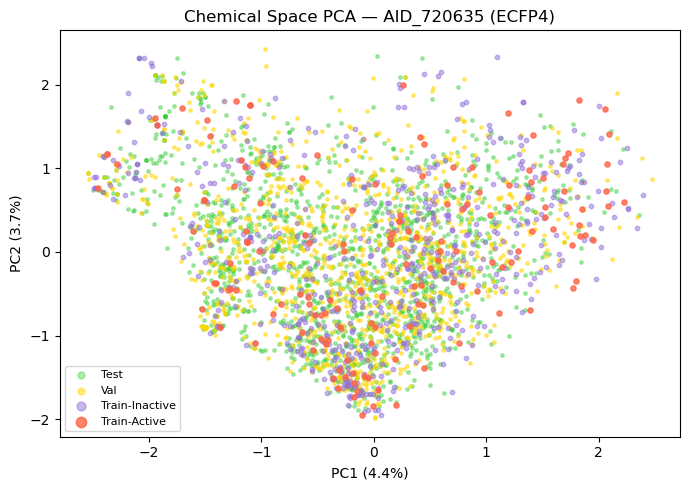

In [41]:
# ── 11. Split Summary & Chemical Space PCA ───────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'act={( ys==1).sum()}, ina={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen', s=6, alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',      s=6, alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-Inactive')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-Active')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — AID_720635 (ECFP4)')
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
plt.savefig('chem_space.png',dpi=150); plt.show()


Left-out inactives : 3,994
PC1: 4.4%  PC2: 3.7%  PC3: 3.2%
Total variance explained: 11.3%


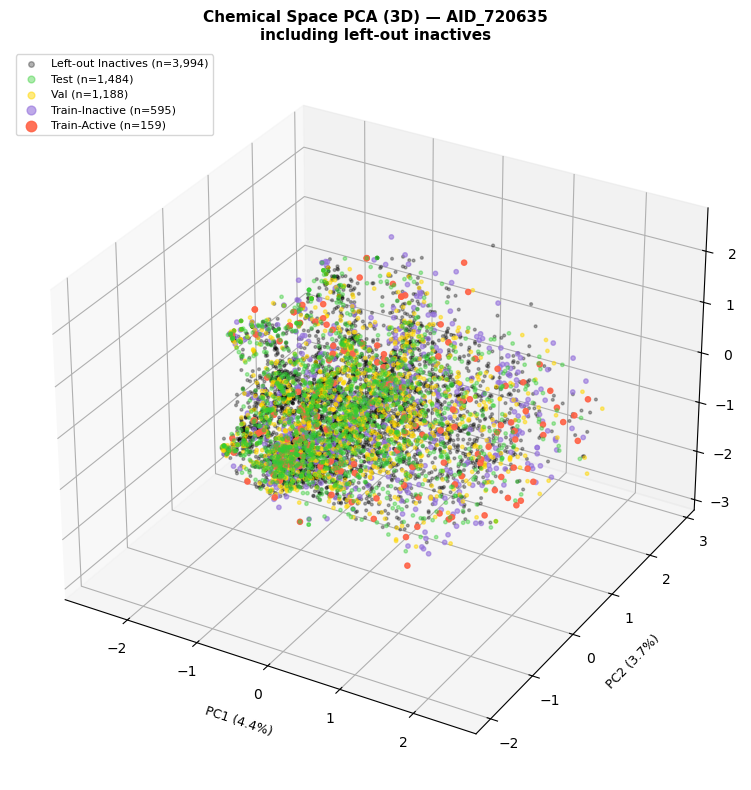

In [42]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# ── Find the left-out (discarded) inactives ──────────────────────────────────
sampled_set     = set(selected_global.tolist())      # kept inactives (NearMiss-3)
leftout_idx_tr  = np.array([idx for idx in ina_idx_tr 
                             if idx not in sampled_set])  # the 1,152 discarded
X_leftout       = X_tr_raw[leftout_idx_tr]           # their fingerprints

print(f'Left-out inactives : {len(leftout_idx_tr):,}')  # inactives NOT selected by NearMiss-3

# ── 3-component PCA ──────────────────────────────────────────────────────────
pca3 = PCA(n_components=3, random_state=SEED)
pca3.fit(X_train)          # fit on balanced training set only

# Transform all sets including leftout
tr_3  = pca3.transform(X_train)    # (1808, 3) balanced train
va_3  = pca3.transform(X_val)      # ( 740, 3) val
te_3  = pca3.transform(X_test)     # ( 925, 3) test
lo_3  = pca3.transform(X_leftout)  # (1152, 3) discarded inactives

pc1_var = pca3.explained_variance_ratio_[0]*100
pc2_var = pca3.explained_variance_ratio_[1]*100
pc3_var = pca3.explained_variance_ratio_[2]*100

print(f'PC1: {pc1_var:.1f}%  PC2: {pc2_var:.1f}%  PC3: {pc3_var:.1f}%')
print(f'Total variance explained: {pc1_var+pc2_var+pc3_var:.1f}%')

# ── 3D Plot ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection='3d')

# Plot each group
ax.scatter(lo_3[:,0], lo_3[:,1], lo_3[:,2],
           c='black', s=4, alpha=0.3, label=f'Left-out Inactives (n={len(lo_3):,})')

ax.scatter(te_3[:,0], te_3[:,1], te_3[:,2],
           c='limegreen', s=6, alpha=0.4, label=f'Test (n={len(te_3):,})')

ax.scatter(va_3[:,0], va_3[:,1], va_3[:,2],
           c='gold', s=6, alpha=0.5, label=f'Val (n={len(va_3):,})')

ax.scatter(tr_3[y_train==0, 0], tr_3[y_train==0, 1], tr_3[y_train==0, 2],
           c='mediumpurple', s=10, alpha=0.6, label=f'Train-Inactive (n={(y_train==0).sum():,})')

ax.scatter(tr_3[y_train==1, 0], tr_3[y_train==1, 1], tr_3[y_train==1, 2],
           c='tomato', s=14, alpha=0.9, label=f'Train-Active (n={(y_train==1).sum():,})')

# Labels
ax.set_xlabel(f'PC1 ({pc1_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_ylabel(f'PC2 ({pc2_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_zlabel(f'PC3 ({pc3_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_title('Chemical Space PCA (3D) — AID_720635\nincluding left-out inactives',
             fontsize=11, fontweight='bold')

ax.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig('chem_space_3d.png', dpi=150)
plt.show()


---
## Step 4 — Evaluation Helpers


In [43]:
# ── 12. Metrics Helper ────────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true,y_pred)*100,1),
        'F1'         : round(f1_score(y_true,y_pred),4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Helpers ready.')


Helpers ready.


---
## Step 5 — Classical ML: Hyperparameter Tuning on Validation Set

Train on balanced training set → tune on (imbalanced) validation set by **ROC-AUC** → final eval on test.


In [44]:
# ── 13. Random Forest Grid Search ────────────────────────────────────────────
# Book p.92: "prefer PR curve whenever the positive class is rare"
# → use PR-AUC (average_precision_score) for model selection, not ROC-AUC
rf_grid = ParameterGrid({
    'n_estimators'    : [300, 500],
    'max_features'    : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'       : [None, 20]
})

best_rf_prauc, best_rf, best_rf_params = 0, None, {}
print(f'RF: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_train, y_train)
    prauc = average_precision_score(y_val, clf.predict_proba(X_val)[:,1])
    if prauc > best_rf_prauc:
        best_rf_prauc, best_rf, best_rf_params = prauc, clf, p

print(f'Best RF  val PR-AUC={best_rf_prauc:.4f}  params={best_rf_params}')


RF: 16 configs...
Best RF  val PR-AUC=0.4070  params={'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}


In [45]:
# ── 14. SVM Grid Search ───────────────────────────────────────────────────────
# Book p.92: prefer PR-AUC for rare positive class
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001]
})

best_svm_prauc, best_svm, best_svm_params = 0, None, {}
print(f'SVM: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_train, y_train)
    prauc = average_precision_score(y_val, clf.predict_proba(X_val)[:,1])
    if prauc > best_svm_prauc:
        best_svm_prauc, best_svm, best_svm_params = prauc, clf, p

print(f'Best SVM val PR-AUC={best_svm_prauc:.4f}  params={best_svm_params}')


SVM: 9 configs...
Best SVM val PR-AUC=0.3392  params={'C': 1, 'gamma': 'scale'}


In [46]:
# ── 15. XGBoost Grid Search ──────────────────────────────────────────────────
# scale_pos_weight: use natural dataset ratio (~28.8) for consistency with GNNs
# Book p.92: prefer PR-AUC for rare positive class model selection
nat_ratio_xgb = (y_tr_raw==0).sum() / (y_tr_raw==1).sum()   # ~28.8

xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8]
})

best_xgb_prauc, best_xgb, best_xgb_params = 0, None, {}
print(f'XGB: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=nat_ratio_xgb, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_train, y_train)
    prauc = average_precision_score(y_val, clf.predict_proba(X_val)[:,1])
    if prauc > best_xgb_prauc:
        best_xgb_prauc, best_xgb, best_xgb_params = prauc, clf, p

print(f'Best XGB val PR-AUC={best_xgb_prauc:.4f}  params={best_xgb_params}')
print(f'XGB scale_pos_weight (natural ratio): {nat_ratio_xgb:.1f}')


XGB: 12 configs...
Best XGB val PR-AUC=0.2447  params={'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 500, 'subsample': 0.8}
XGB scale_pos_weight (natural ratio): 28.9


In [47]:
# ── 16. Classical ML — Val & Test Evaluation ─────────────────────────────────
classical = {'Random Forest': best_rf, 'SVM': best_svm, 'XGBoost': best_xgb}
cl_probs_val  = {n: clf.predict_proba(X_val)[:,1]  for n,clf in classical.items()}
cl_probs_test = {n: clf.predict_proba(X_test)[:,1] for n,clf in classical.items()}

rows_val, rows_test = [], []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_val.append(evaluate(y_val,  cl_probs_val[name],  name, cpt))
        rows_test.append(evaluate(y_test, cl_probs_test[name], name, cpt))

df_cl_val  = pd.DataFrame(rows_val)[METRIC_COLS]
df_cl_test = pd.DataFrame(rows_test)[METRIC_COLS]

print('── Classical ML — Validation Set ──')
display(df_cl_val.set_index(['Model','CPT']))
print('\n── Classical ML — Test Set ──')
display(df_cl_test.set_index(['Model','CPT']))


── Classical ML — Validation Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         20.0         99.9  60.0   0.8141  0.4070  0.4142   
              0.8          2.5        100.0  51.2   0.8141  0.4070  0.1555   
SVM           0.5          0.0        100.0  50.0   0.8308  0.3392  0.0000   
              0.8          0.0        100.0  50.0   0.8308  0.3392  0.0000   
XGBoost       0.5         45.0         87.9  66.4   0.6999  0.2447  0.1752   
              0.8         30.0         95.2  62.6   0.6999  0.2447  0.1971   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     60.0  0.3265  
              0.8     51.2  0.0488  
SVM           0.5     50.0  0.0000  
              0.8     50.0  0.0000  
XGBoost       0.5     66.4  0.1827  
              0.8     62.6  0.2243


── Classical ML — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         20.0         99.5  59.8   0.7931  0.3108  0.3308   
              0.8          2.0        100.0  51.0   0.7931  0.3108  0.1391   
SVM           0.5          0.0        100.0  50.0   0.7886  0.2494  0.0000   
              0.8          0.0        100.0  50.0   0.7886  0.2494  0.0000   
XGBoost       0.5         48.0         85.3  66.6   0.7495  0.1650  0.1645   
              0.8         30.0         94.6  62.3   0.7495  0.1650  0.1828   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     59.8  0.2985  
              0.8     51.0  0.0392  
SVM           0.5     50.0  0.0000  
              0.8     50.0  0.0000  
XGBoost       0.5     66.6  0.1684  
              0.8     62.3  0.2098

---
## Step 6 — Graph Neural Networks (Classification)

**Architecture** (same for all 4 variants):
```
SMILES  Atoms+Bonds (27-dim / 6-dim)
  - Linear projection (hidden)
  - 3 × [Conv + BatchNorm1d + ReLU + Dropout + Residual]
  - GlobalMeanPool
  - MLP head [hidden→hidden/2→1]
  - BCEWithLogitsLoss
```
Tuned hyperparameters per architecture: `hidden`, `n_layers`, `dropout`, `lr`  
Selection criterion: **val ROC-AUC** | Early stopping patience=20 epochs


In [48]:
# ── 17. GNN Architecture ─────────────────────────────────────────────────────
class MolGNN(nn.Module):
    """
     GNN for molecular binary classification.
     GCN, GAT, GIN, GraphSAGE via conv_type argument.
    3 conv layers with BatchNorm + Residual connections.
    """

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.drop      = nn.Dropout(dropout)

        # Input projection
        self.proj = nn.Linear(in_dim, hidden) #linear layer to project input features to hidden dim
        self.bn0  = nn.BatchNorm1d(hidden) #batch norm after input projection

        # Conv layers + BatchNorm
        self.convs = nn.ModuleList() #list to hold convolutional layers
        self.bns   = nn.ModuleList() #list to hold batch norm layers after each conv
        for _ in range(n_layers): 
#             GCNConv(128, 128):
# Each atom collects messages from neighbours
# → takes weighted average
# → updates its own 128 numbers

            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                # concat=False → output stays at hidden dim
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(
                    nn.Linear(hidden, hidden*2),
                    nn.BatchNorm1d(hidden*2),
                    nn.ReLU(),
                    nn.Linear(hidden*2, hidden))
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        # MLP classification head
        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden//2, 1)   # logit output for BCEWithLogitsLoss
        )

    def forward(self, x, edge_index, batch):
        # Input projection
        x = F.relu(self.bn0(self.proj(x)))
        x = self.drop(x)
        # Conv layers with residual connections
        for conv, bn in zip(self.convs, self.bns):
            x_res = x
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = self.drop(x)
            x = x + x_res          # skip connection (same dim)
        # Global readout + head
        x = global_mean_pool(x, batch)
        return self.head(x).squeeze(-1)   # (B,)

print(f'MolGNN defined. ATOM_DIM={ATOM_DIM}')


MolGNN defined. ATOM_DIM=27


In [49]:
# ── 18. Training & Evaluation Functions ──────────────────────────────────────
def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss   = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    """Returns: probs, labels, roc_auc, pr_auc
    Book p.92: PR-AUC is primary metric for rare positive class.
    Both are returned so learning curves can show PR-AUC for model selection.
    """
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    roc    = roc_auc_score(labels, probs)
    pr     = average_precision_score(labels, probs)
    return probs, labels, roc, pr

print('Training helpers defined.')


Training helpers defined.


In [50]:
# ── 19. GNN DataLoaders ──────────────────────────────────────────────────────
BATCH = 64
train_loader = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)

# pos_weight = NATURAL dataset ratio (from full training pool, ~28.8:1)
# Reflects real-world deployment imbalance regardless of training ratio used
nat_ratio  = (y_tr_raw==0).sum() / (y_tr_raw==1).sum()
pos_weight = torch.tensor([nat_ratio], device=DEVICE)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f'Train graphs : {len(graphs_train)}')
print(f'Val   graphs : {len(graphs_val)}')
print(f'Test  graphs : {len(graphs_test)}')
print(f'pos_weight   : {pos_weight.item():.3f}  (natural ratio ~28.8:1, not training ratio)')


Train graphs : 754
Val   graphs : 1188
Test  graphs : 1484
pos_weight   : 28.862  (natural ratio ~28.8:1, not training ratio)


In [51]:
# ── 20. Hyperparameter Grid & Training Loop ──────────────────────────────────
# Book p.92: "prefer PR curve when positive class is rare"
# Early stopping and model selection based on val PR-AUC, not ROC-AUC.
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

MAX_EPOCHS = 100
PATIENCE   = 20   # early stopping patience

gnn_best_models   = {}   # best state_dict per architecture
gnn_best_configs  = {}   # best hyperparams per architecture
gnn_best_val_pr   = {}   # best val PR-AUC per architecture
gnn_history       = {}   # training curves (pr_auc)

for arch, configs in GNN_CONFIGS.items():
    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_pr, best_state, best_cfg = 0, None, {}

    for cfg in configs:
        heads = cfg.pop('heads', 4)
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch, heads=heads).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
        # ReduceLROnPlateau monitors val PR-AUC (mode='max')
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    opt, mode='max', factor=0.5, patience=10)
        cfg['heads'] = heads  # restore

        best_ep_pr, no_improv = 0, 0
        best_ep_state = None
        train_prs, val_prs = [], []

        for epoch in range(1, MAX_EPOCHS+1):
            loss = gnn_train_epoch(model, train_loader, opt, criterion, DEVICE)
            _,_, tr_roc, tr_pr = gnn_eval(model, train_loader, DEVICE)
            _,_, va_roc, va_pr = gnn_eval(model, val_loader,   DEVICE)
            sched.step(va_pr)          # scheduler monitors PR-AUC
            train_prs.append(tr_pr); val_prs.append(va_pr)
            if va_pr > best_ep_pr:
                best_ep_pr    = va_pr
                best_ep_state = copy.deepcopy(model.state_dict())
                no_improv     = 0
            else:
                no_improv += 1
            if no_improv >= PATIENCE:
                break

        if best_ep_pr > best_pr:
            best_pr    = best_ep_pr
            best_state = best_ep_state
            best_cfg   = cfg.copy()
            gnn_history[arch] = (train_prs, val_prs)

        cfg_str = {k:v for k,v in cfg.items()}
        print(f'  {cfg_str}  →  val PR-AUC={best_ep_pr:.4f}  stopped@ep{len(train_prs)}')

    gnn_best_val_pr[arch]   = best_pr
    gnn_best_configs[arch]  = best_cfg
    gnn_best_models[arch]   = best_state
    print(f'>> Best {arch}: PR-AUC={best_pr:.4f}  cfg={best_cfg}')



Architecture: GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val PR-AUC=0.2376  stopped@ep87
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val PR-AUC=0.2293  stopped@ep49
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  →  val PR-AUC=0.1547  stopped@ep70
>> Best GCN: PR-AUC=0.2376  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val PR-AUC=0.2181  stopped@ep61
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  →  val PR-AUC=0.2145  stopped@ep73
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val PR-AUC=0.2089  stopped@ep46
>> Best GAT: PR-AUC=0.2181  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, '

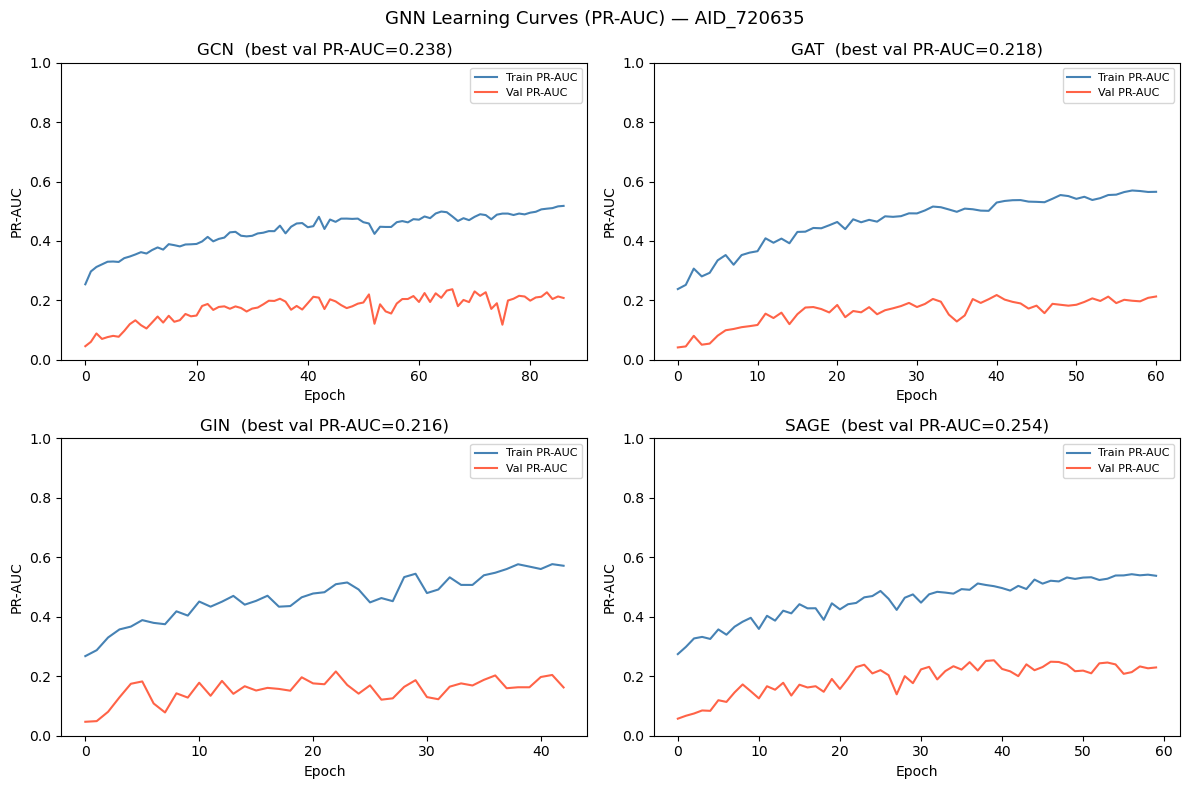

In [52]:
# ── 21. Learning Curves (PR-AUC) ─────────────────────────────────────────────
# Book p.92: PR-AUC is primary metric for rare positive class.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in gnn_history:
        tr, va = gnn_history[arch]
        ax.plot(tr, label='Train PR-AUC', color='steelblue')
        ax.plot(va, label='Val PR-AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val PR-AUC={gnn_best_val_pr[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('PR-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.0, 1.0)
plt.suptitle('GNN Learning Curves (PR-AUC) — AID_720635', fontsize=13)
plt.tight_layout(); plt.savefig('gnn_learning_curves.png',dpi=150); plt.show()


In [53]:
# ── 22. GNN Test & Val Evaluation ────────────────────────────────────────────
gnn_probs_test = {}
gnn_probs_val  = {}

for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)

    probs_te, _, _, _ = gnn_eval(model, test_loader, DEVICE)
    probs_va, _, _, _ = gnn_eval(model, val_loader,  DEVICE)
    gnn_probs_test[arch] = probs_te
    gnn_probs_val[arch]  = probs_va

rows_gnn = []
for arch, prob in gnn_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows_gnn.append(evaluate(y_test, prob, arch, cpt))

df_gnn_test = pd.DataFrame(rows_gnn)[METRIC_COLS]
print('── GNN — Test Set ──')
display(df_gnn_test.set_index(['Model','CPT']))


── GNN — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         92.0         35.6  63.8   0.7402  0.1103  0.1045     63.8   
      0.8         62.0         66.2  64.1   0.7402  0.1103  0.1068     64.1   
GAT   0.5         96.0         15.1  55.5   0.7225  0.1153  0.0564     55.5   
      0.8         76.0         59.6  67.8   0.7225  0.1153  0.1301     67.8   
GIN   0.5         98.0         11.4  54.7   0.7065  0.1161  0.0542     54.7   
      0.8         66.0         56.2  61.1   0.7065  0.1161  0.0806     61.1   
SAGE  0.5         94.0         31.2  62.6   0.7350  0.1021  0.0988     62.6   
      0.8         72.0         58.6  65.3   0.7350  0.1021  0.1119     65.3   

               F1  
Model CPT          
GCN   0.5  0.0902  
      0.8  0.1095  
GAT   0.5  0.0729  
      0.8  0.1138  
GIN   0.5  0.0716  
      0.8  0.0928  
SAGE  0.5  0.0867  
      0.8  0.1060

---
## Step 7 — Consensus Model (All Classical + GNN)


In [54]:
# ── 23. Consensus: Average All Model Probabilities ───────────────────────────
all_test_probs = {**cl_probs_test, **gnn_probs_test}

consensus_prob = np.mean(list(all_test_probs.values()), axis=0)
all_test_probs['Consensus'] = consensus_prob

# Classical-only consensus
cl_consensus  = np.mean(list(cl_probs_test.values()), axis=0)
all_test_probs['Consensus-Classical'] = cl_consensus

# GNN-only consensus
gnn_consensus = np.mean(list(gnn_probs_test.values()), axis=0)
all_test_probs['Consensus-GNN'] = gnn_consensus

final_rows = []
for name, prob in all_test_probs.items():
    for cpt in [0.5, 0.8]:
        final_rows.append(evaluate(y_test, prob, name, cpt))

df_final = pd.DataFrame(final_rows)[METRIC_COLS]
print('── FULL TEST SET COMPARISON ──')
display(df_final.set_index(['Model','CPT'])) #to check if we can 3rd categoruy for inactive


── FULL TEST SET COMPARISON ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Random Forest       0.5         20.0         99.5  59.8   0.7931  0.3108   
                    0.8          2.0        100.0  51.0   0.7931  0.3108   
SVM                 0.5          0.0        100.0  50.0   0.7886  0.2494   
                    0.8          0.0        100.0  50.0   0.7886  0.2494   
XGBoost             0.5         48.0         85.3  66.6   0.7495  0.1650   
                    0.8         30.0         94.6  62.3   0.7495  0.1650   
GCN                 0.5         92.0         35.6  63.8   0.7402  0.1103   
                    0.8         62.0         66.2  64.1   0.7402  0.1103   
GAT                 0.5         96.0         15.1  55.5   0.7225  0.1153   
                    0.8         76.0         59.6  67.8   0.7225  0.1153   
GIN                 0.5         98.0         11.4  54.7   0.7065  0.1161   
                    0.8         66.0         56.2  61.1   0.7065  0.1161   
SAGE                0.5         94.0         31.2  62.6   0.7350  0.1021   
                    0.8         72.0         58.6  65.3   0.7350  0.1021   
Consensus           0.5         82.0         48.5  65.3   0.7912  0.2384   
                    0.8         18.0         99.6  58.8   0.7912  0.2384   
Consensus-Classical 0.5         28.0         96.2  62.1   0.7781  0.2565   
                    0.8          0.0        100.0  50.0   0.7781  0.2565   
Consensus-GNN       0.5         96.0         24.4  60.2   0.7435  0.1448   
                    0.8         64.0         63.4  63.7   0.7435  0.1448   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Random Forest       0.5  0.3308     59.8  0.2985  
                    0.8  0.1391     51.0  0.0392  
SVM                 0.5  0.0000     50.0  0.0000  
                    0.8  0.0000     50.0  0.0000  
XGBoost             0.5  0.1645     66.6  0.1684  
                    0.8  0.1828     62.3  0.2098  
GCN                 0.5  0.1045     63.8  0.0902  
                    0.8  0.1068     64.1  0.1095  
GAT                 0.5  0.0564     55.5  0.0729  
                    0.8  0.1301     67.8  0.1138  
GIN                 0.5  0.0542     54.7  0.0716  
                    0.8  0.0806     61.1  0.0928  
SAGE                0.5  0.0988     62.6  0.0867  
                    0.8  0.1119     65.3  0.1060  
Consensus           0.5  0.1103     65.3  0.0989  
                    0.8  0.3171     58.8  0.2769  
Consensus-Classical 0.5  0.2071     62.1  0.2353  
                    0.8  0.0000     50.0  0.0000  
Consensus-GNN       0.5  0.0866     60.2  0.0812  
                    0.8  0.1021     63.7  0.1054

In [55]:
# ── 23b. PR Curve Threshold Optimization ────────────────────────────────────
# Hands-On ML (p.87-89): For rare positive class, find threshold that
# maximises F1 on the NATURAL validation set (real-world 29:1 ratio).
# Then apply those thresholds to the test set for final evaluation.

all_val_probs = {**cl_probs_val, **gnn_probs_val}
all_val_probs['Consensus']           = np.mean(list({**cl_probs_val,
                                                      **gnn_probs_val}.values()), axis=0)
all_val_probs['Consensus-Classical'] = np.mean(list(cl_probs_val.values()), axis=0)
all_val_probs['Consensus-GNN']       = np.mean(list(gnn_probs_val.values()), axis=0)

opt_thresholds = {}
print(f'{"Model":<25} {"Opt Thr":>8} {"Val F1":>7} {"Val Sens":>9} {"Val Spec":>9}')
print('-' * 65)

for name, prob in all_val_probs.items():
    prec, rec, thrs = precision_recall_curve(y_val, prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-8)
    best_idx = np.argmax(f1[:-1])   # last element has no matching threshold
    best_thr = float(thrs[best_idx])
    best_f1  = float(f1[best_idx])

    y_opt = (prob >= best_thr).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_val, y_opt).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    opt_thresholds[name] = best_thr
    print(f'{name:<25} {best_thr:>8.4f} {best_f1:>7.4f} {sens*100:>8.1f}% {spec*100:>8.1f}%')

# Apply optimal thresholds to TEST SET
print(f'\n── TEST SET — Optimal PR-Curve Thresholds ──')
opt_rows = []
for name, prob in all_test_probs.items():
    if name in opt_thresholds:
        cpt = opt_thresholds[name]
        opt_rows.append(evaluate(y_test, prob, name, cpt=round(cpt, 4)))

df_opt = pd.DataFrame(opt_rows)[METRIC_COLS]
display(df_opt.set_index(['Model', 'CPT']))


Model                      Opt Thr  Val F1  Val Sens  Val Spec
-----------------------------------------------------------------
Random Forest               0.4207  0.4474     42.5%     98.3%
SVM                         0.3197  0.3860     27.5%     99.5%
XGBoost                     0.9696  0.2857     20.0%     99.3%
GCN                         0.9353  0.2836     47.5%     93.5%
GAT                         0.9816  0.2807     20.0%     99.2%
GIN                         0.9706  0.2712     20.0%     99.0%
SAGE                        0.9553  0.2947     35.0%     96.4%
Consensus                   0.7483  0.4058     35.0%     98.7%
Consensus-Classical         0.5440  0.3667     27.5%     99.2%
Consensus-GNN               0.9540  0.3000     30.0%     97.6%

── TEST SET — Optimal PR-Curve Thresholds ──


,,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,CPT,,,,,,,,
Random Forest,0.4207,30.0,97.2,63.6,0.7931,0.3108,0.2599,63.6,0.2857
SVM,0.3197,18.0,99.0,58.5,0.7886,0.2494,0.2425,58.5,0.2432
XGBoost,0.9696,20.0,98.7,59.4,0.7495,0.1650,0.2486,59.4,0.2564
GCN,0.9353,28.0,92.4,60.2,0.7402,0.1103,0.1335,60.2,0.1618
GAT,0.9816,8.0,99.1,53.5,0.7225,0.1153,0.1203,53.5,0.1194
GIN,0.9706,10.0,98.2,54.1,0.7065,0.1161,0.1033,54.1,0.1235
SAGE,0.9553,18.0,95.5,56.8,0.7350,0.1021,0.1129,56.8,0.1463
Consensus,0.7483,26.0,98.0,62.0,0.7912,0.2384,0.2647,62.0,0.2857
Consensus-Classical,0.5440,22.0,98.6,60.3,0.7781,0.2565,0.2600,60.3,0.2716


---
## Step 8 — Applicability Domain


AD threshold  : 0.6191
Test in AD    : 431/1484 (29.0%)
  AD-filtered Sensitivity: 81.8
  AD-filtered Specificity: 54.5
  AD-filtered CCR: 68.2
  AD-filtered ROC-AUC: 0.8168
  AD-filtered MCC: 0.1602


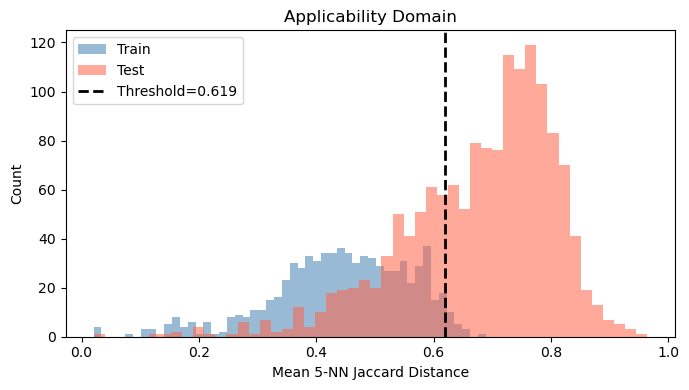

In [56]:
# ── 24. AD — k-NN Jaccard ────────────────────────────────────────────────────
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_train)
d_tr, _ = nn_ad.kneighbors(X_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_test)
md_te   = d_te.mean(axis=1)
in_ad   = md_te <= ad_thr
cov     = in_ad.mean()*100

print(f'AD threshold  : {ad_thr:.4f}')
print(f'Test in AD    : {in_ad.sum()}/{len(y_test)} ({cov:.1f}%)')

if in_ad.sum() >= 20:
    m = evaluate(y_test[in_ad], consensus_prob[in_ad], 'Consensus AD', cpt=0.5)
    for k in ['Sensitivity','Specificity','CCR','ROC-AUC','MCC']:
        print(f'  AD-filtered {k}: {m[k]}')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(md_tr, bins=50, alpha=0.55, color='steelblue', label='Train')
ax.hist(md_te, bins=50, alpha=0.55, color='tomato',    label='Test')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2,
           label=f'Threshold={ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain'); ax.legend()
plt.tight_layout(); plt.savefig('ad_dist.png',dpi=150); plt.show()


---
## Step 9 — Final Summary


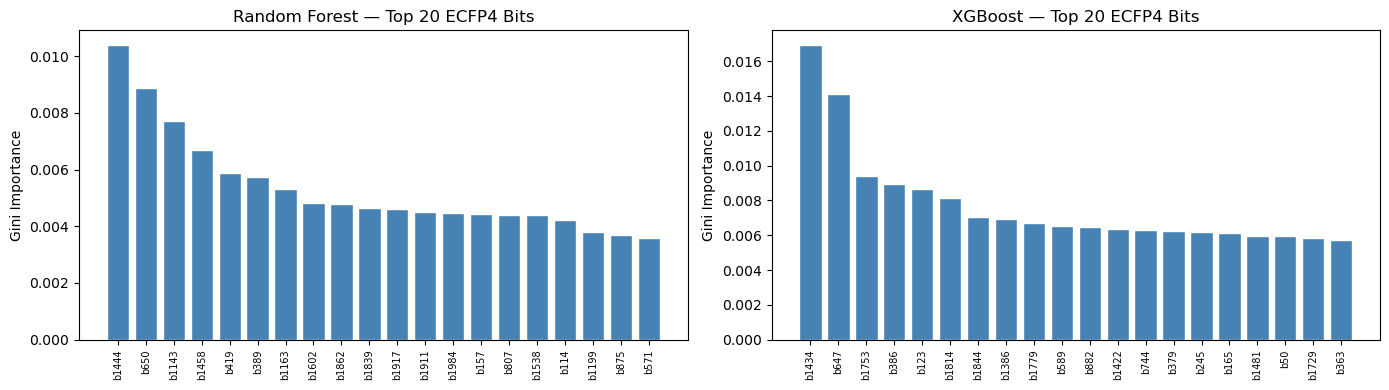

In [57]:
# ── 25. Feature Importance — RF & XGBoost ────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax,(name,clf) in zip(axes,[('Random Forest',best_rf),('XGBoost',best_xgb)]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    ax.bar(range(20), imp[top], color='steelblue', edgecolor='white')
    ax.set_xticks(range(20))
    ax.set_xticklabels([f'b{i}' for i in top], rotation=90, fontsize=7)
    ax.set_title(f'{name} — Top 20 ECFP4 Bits'); ax.set_ylabel('Gini Importance')
plt.tight_layout(); plt.savefig('feat_importance.png',dpi=150); plt.show()


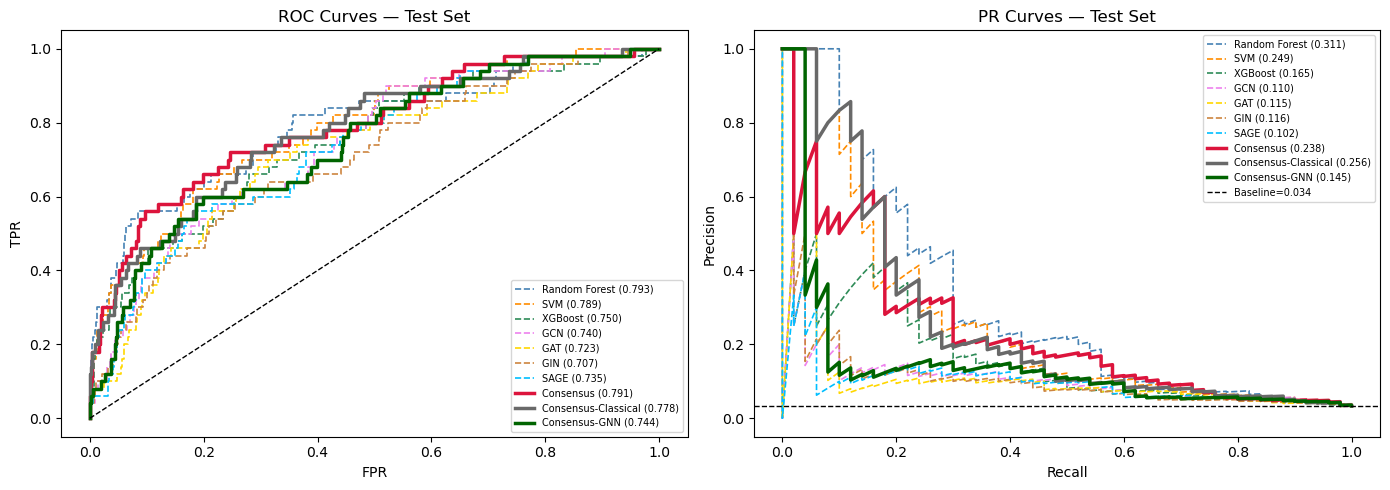

In [58]:
# ── 26. ROC Curves — All Models ──────────────────────────────────────────────
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
          'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
          'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1,2,figsize=(14,5))
for name, prob in all_test_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS.get(name,'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr,tpr,_ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr,tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec,pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Test Set'); axes[0].legend(fontsize=7,loc='lower right')

axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Baseline={y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Test Set'); axes[1].legend(fontsize=7,loc='upper right')

plt.tight_layout(); plt.savefig('roc_pr_all.png',dpi=150); plt.show()


In [59]:
# ── 27. Ranked Summary Table — sorted by PR-AUC ─────────────────────────────
# Book p.92: "prefer PR curve when positive class is rare"
# Primary sort key: PR-AUC (not ROC-AUC)
summary_cpt1   = df_final[df_final['CPT']==0.5].drop(columns='CPT').set_index('Model')
summary_sorted = summary_cpt1.sort_values('PR-AUC', ascending=False)
print('═'*90)
print('FINAL RANKING — AID_720635 Caspase/HepG2 (CPT=0.50, sorted by PR-AUC)')
print('NearMiss-3 downsampling | pos_weight=natural ratio | PR-curve threshold tuning')
print('Book ref: Hands-On ML p.92 — PR-AUC preferred for rare positive class')
print('═'*90)
display(summary_sorted)

print(f'\nApplicability Domain coverage: {cov:.1f}%')
summary_sorted.to_csv('qsar_mito_final_results.csv')
print('Saved → qsar_mito_final_results.csv')


══════════════════════════════════════════════════════════════════════════════════════════
FINAL RANKING — AID_720635 Caspase/HepG2 (CPT=0.50, sorted by PR-AUC)
NearMiss-3 downsampling | pos_weight=natural ratio | PR-curve threshold tuning
Book ref: Hands-On ML p.92 — PR-AUC preferred for rare positive class
══════════════════════════════════════════════════════════════════════════════════════════


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Random Forest,20.0,99.5,59.8,0.7931,0.3108,0.3308,59.8,0.2985
Consensus-Classical,28.0,96.2,62.1,0.7781,0.2565,0.2071,62.1,0.2353
SVM,0.0,100.0,50.0,0.7886,0.2494,0.0000,50.0,0.0000
Consensus,82.0,48.5,65.3,0.7912,0.2384,0.1103,65.3,0.0989
XGBoost,48.0,85.3,66.6,0.7495,0.1650,0.1645,66.6,0.1684
Consensus-GNN,96.0,24.4,60.2,0.7435,0.1448,0.0866,60.2,0.0812
GIN,98.0,11.4,54.7,0.7065,0.1161,0.0542,54.7,0.0716
GAT,96.0,15.1,55.5,0.7225,0.1153,0.0564,55.5,0.0729
GCN,92.0,35.6,63.8,0.7402,0.1103,0.1045,63.8,0.0902



Applicability Domain coverage: 29.0%
Saved → qsar_mito_final_results.csv


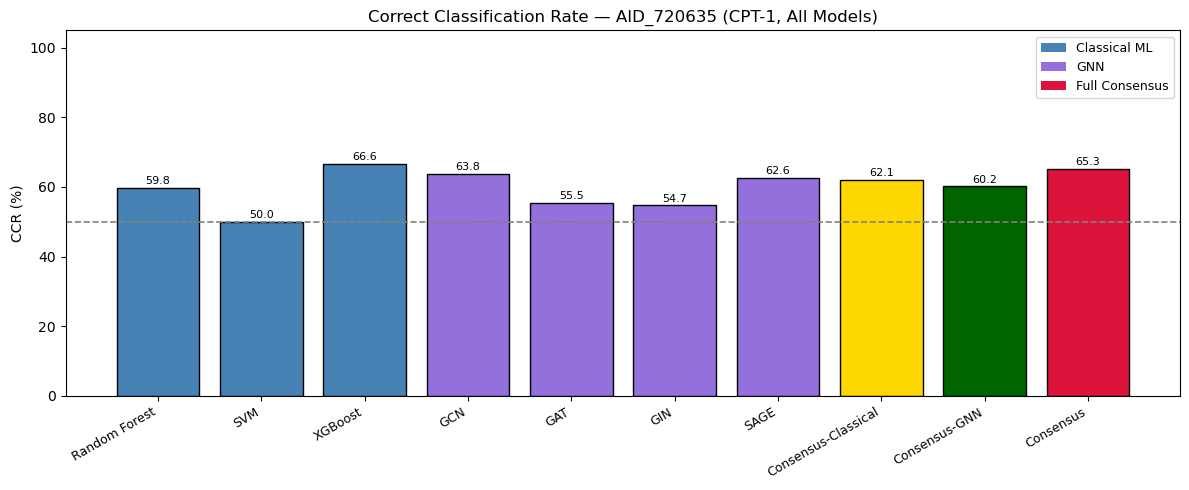

In [60]:
# ── 28. CCR Comparison Bar Chart ─────────────────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals = [summary_cpt1.loc[m,'CCR'] if m in summary_cpt1.index else 0 for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0,105)
ax.set_title('Correct Classification Rate — AID_720635 (CPT-1, All Models)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
ax.legend()
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus')]
ax.legend(handles=legend_elements, fontsize=9)
plt.tight_layout(); plt.savefig('ccr_all_models.png',dpi=150); plt.show()


Best model (ROC-AUC): Random Forest
              precision    recall  f1-score   support

 Inactive(0)       0.97      1.00      0.98      1434
   Active(1)       0.59      0.20      0.30        50

    accuracy                           0.97      1484
   macro avg       0.78      0.60      0.64      1484
weighted avg       0.96      0.97      0.96      1484



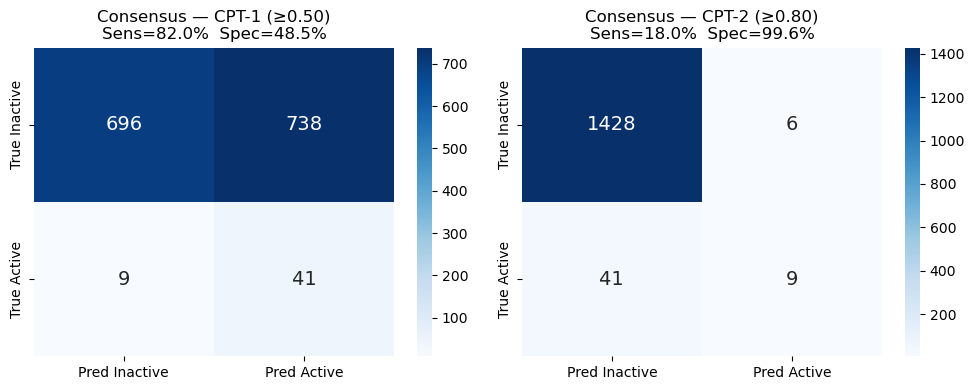

In [61]:
# ── 29. Best Model Report ─────────────────────────────────────────────────────
best_name = summary_sorted.index[0]
best_prob = all_test_probs[best_name]
best_pred = (best_prob >= 0.5).astype(int)
print(f'Best model (ROC-AUC): {best_name}')
print(classification_report(y_test, best_pred, target_names=['Inactive(0)','Active(1)']))

# Confusion matrix
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, cpt, label in zip(axes,[0.5,0.8],['CPT-1 (≥0.50)','CPT-2 (≥0.80)']):
    pred = (consensus_prob >= cpt).astype(int)
    cm   = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred Inactive','Pred Active'],
                yticklabels=['True Inactive','True Active'], annot_kws={'size':14})
    tn,fp,fn,tp = cm.ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp)
    ax.set_title(f'Consensus — {label}\nSens={sens*100:.1f}%  Spec={spec*100:.1f}%')
plt.tight_layout(); plt.savefig('confusion_final.png',dpi=150); plt.show()


---
## Step 10 — Single Compound Prediction

Paste any SMILES below to run it through all 7 trained models and get a consensus toxicity prediction.


Compound : Nc1ccc(-c2ccc(F)cc2)cc1
Canonical: Nc1ccc(-c2ccc(F)cc2)cc1
Mol. Weight: 187.22 Da  |  Atoms: 14

════════════════════════════════════════════════════════════
 INDIVIDUAL MODEL PROBABILITIES (P(Active))
════════════════════════════════════════════════════════════
  Model                   P(Active)    CPT-1    CPT-2
  -------------------------------------------------------
  Random Forest              0.2967  inactive  inactive  
  SVM                        0.1656  inactive  inactive  
  XGBoost                    0.0131  inactive  inactive  
  GCN                        0.8461   ACTIVE   ACTIVE  
  GAT                        0.7697   ACTIVE  inactive  
  GIN                        0.8194   ACTIVE   ACTIVE  
  SAGE                       0.8875   ACTIVE   ACTIVE  
  Consensus-Classical        0.1585  inactive  inactive  
  Consensus-GNN              0.8307   ACTIVE   ACTIVE  
  CONSENSUS (all 7)          0.5426   ACTIVE  inactive  ◄◄
══════════════════════════════════════════

[09:13:39] DEPRECATION WARNING: please use MorganGenerator


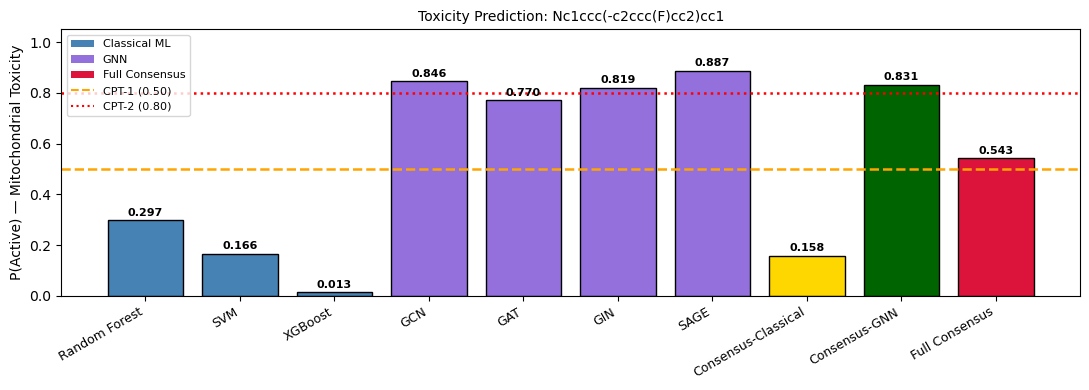

In [62]:
# ── 30. Single Compound Prediction ───────────────────────────────────────────
# ► Change TEST_SMILES to any molecule you want to predict.
# ► Set TRUE_LABEL = 1 (Active) or 0 (Inactive) if you know it, else None.
# ─────────────────────────────────────────────────────────────────────────────

from rdkit.Chem import Descriptors   # needed for MolWt

TEST_SMILES  = "Nc1ccc(-c2ccc(F)cc2)cc1"  
TRUE_LABEL   = None                       

# ── Step A: Parse & canonicalise ─────────────────────────────────────────────
mol = Chem.MolFromSmiles(TEST_SMILES)
if mol is None:
    raise ValueError(f"RDKit could not parse SMILES: {TEST_SMILES!r}  — check for typos.")

canon = Chem.MolToSmiles(mol)
mw    = Descriptors.MolWt(mol)
print(f"Compound : {TEST_SMILES}")
print(f"Canonical: {canon}")
print(f"Mol. Weight: {mw:.2f} Da  |  Atoms: {mol.GetNumAtoms()}")

# ── Step B: Morgan fingerprint (for classical ML + AD) ────────────────────────
fp_arr = smiles_to_ecfp4(canon)          # reuses function from Cell 5
X_query = fp_arr.reshape(1, -1)          # shape (1, 2048)

# ── Step C: Build graph (for GNN) ─────────────────────────────────────────────
graph_query = mol_to_graph(canon, label=0)   # label=0 is placeholder
query_loader = DataLoader([graph_query], batch_size=1, shuffle=False)

# ── Step D: Classical ML probabilities ────────────────────────────────────────
cl_query_probs = {}
for name, clf in classical.items():                # RF, SVM, XGBoost
    cl_query_probs[name] = float(clf.predict_proba(X_query)[0, 1])

# ── Step E: GNN probabilities ─────────────────────────────────────────────────
gnn_query_probs = {}
for arch, state in gnn_best_models.items():        # GCN, GAT, GIN, SAGE
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        batch = next(iter(query_loader)).to(DEVICE)
        logit = model(batch.x, batch.edge_index, batch.batch)
        gnn_query_probs[arch] = float(torch.sigmoid(logit).item())

# ── Step F: Consensus ─────────────────────────────────────────────────────────
all_query_probs = {**cl_query_probs, **gnn_query_probs}
consensus_q     = float(np.mean(list(all_query_probs.values())))
cl_consensus_q  = float(np.mean(list(cl_query_probs.values())))
gnn_consensus_q = float(np.mean(list(gnn_query_probs.values())))

# ── Step G: Applicability Domain check ───────────────────────────────────────
d_query, _ = nn_ad.kneighbors(X_query)
md_query   = float(d_query.mean())
in_domain  = md_query <= ad_thr

# ── Step H: Pretty print ─────────────────────────────────────────────────────
print("\n" + "═"*60)
print(" INDIVIDUAL MODEL PROBABILITIES (P(Active))")
print("═"*60)
print(f"  {'Model':<22} {'P(Active)':>10}  {'CPT-1':>7}  {'CPT-2':>7}")
print("  " + "-"*55)
for name, p in {**all_query_probs,
                'Consensus-Classical': cl_consensus_q,
                'Consensus-GNN'      : gnn_consensus_q,
                'CONSENSUS (all 7)'  : consensus_q}.items():
    pred1 = "ACTIVE" if p >= 0.5 else "inactive"
    pred2 = "ACTIVE" if p >= 0.8 else "inactive"
    marker = "◄◄" if "CONSENSUS" in name else ""
    print(f"  {name:<22} {p:>10.4f}  {pred1:>7}  {pred2:>7}  {marker}")

print("═"*60)
print(f"\n  CONSENSUS PROBABILITY : {consensus_q:.4f}")

cpt1_call = "⚠  ACTIVE (Mitochondrially Toxic)" if consensus_q >= 0.5 else "✓  INACTIVE (Non-Toxic)"
cpt2_call = "⚠  ACTIVE (High-confidence)"        if consensus_q >= 0.8 else "✓  INACTIVE / uncertain"

print(f"  CPT-1 (≥0.50) verdict: {cpt1_call}")
print(f"  CPT-2 (≥0.80) verdict: {cpt2_call}")

ad_msg = f"INSIDE applicability domain  (dist={md_query:.4f} ≤ {ad_thr:.4f})" \
         if in_domain else \
         f"OUTSIDE applicability domain (dist={md_query:.4f} > {ad_thr:.4f}) — prediction may be unreliable"
print(f"\n  AD check   : {ad_msg}")

if TRUE_LABEL is not None:
    lbl_str = "Active (1)" if TRUE_LABEL == 1 else "Inactive (0)"
    correct = (consensus_q >= 0.5) == (TRUE_LABEL == 1)
    print(f"\n  True label : {lbl_str}  →  Prediction {'CORRECT ✓' if correct else 'WRONG ✗'}")

print("═"*60)

# ── Step I: Bar chart ─────────────────────────────────────────────────────────
plot_names  = list(all_query_probs.keys()) + ['Consensus-Classical','Consensus-GNN','Full Consensus']
plot_probs  = list(all_query_probs.values()) + [cl_consensus_q, gnn_consensus_q, consensus_q]
plot_colors = (['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson'])

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(plot_names, plot_probs, color=plot_colors, edgecolor='black')
ax.axhline(0.5, color='orange', lw=1.8, ls='--', label='CPT-1 (0.50)')
ax.axhline(0.8, color='red',    lw=1.8, ls=':',  label='CPT-2 (0.80)')
for b, p in zip(bars, plot_probs):
    ax.text(b.get_x() + b.get_width()/2, p + 0.01, f'{p:.3f}',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_ylabel('P(Active) — Mitochondrial Toxicity')
ax.set_title(f'Toxicity Prediction: {canon}', fontsize=10)
ax.set_xticklabels(plot_names, rotation=30, ha='right', fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus'),
                   plt.Line2D([0],[0],color='orange',ls='--',label='CPT-1 (0.50)'),
                   plt.Line2D([0],[0],color='red',   ls=':' ,label='CPT-2 (0.80)')],
          fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('single_compound_prediction.png', dpi=150)
plt.show()
